# Tugas Modul 9 - Basis Data Perpustakaan dengan SQLite
Nama : Dafiq Bisma Al Alawy  
NIM  : 411232060

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Soal 1

In [2]:
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON")

cursor.execute("DROP TABLE IF EXISTS peminjaman")
cursor.execute("DROP TABLE IF EXISTS buku")
cursor.execute("DROP TABLE IF EXISTS anggota")

cursor.execute('''
CREATE TABLE buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT,
    tahun INTEGER
)
''')

cursor.execute('''
CREATE TABLE anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT
)
''')

cursor.execute('''
CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
''')
conn.commit()

### a. Tambah data buku dan anggota

In [3]:
buku = [
    (1, 'Laskar Pelangi', 'Andrea Hirata', 2005),
    (2, 'Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    (3, 'Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    (4, 'Filosofi Teras', 'Henry Manampiring', 2018),
    (5, 'Pengantar Basis Data', 'Abdul Kadir', 2014)
]
cursor.executemany("INSERT INTO buku VALUES (?, ?, ?, ?)", buku)

anggota = [
    (1, 'Andi', 'andi@gmail.com'),
    (2, 'Siti', 'siti@gmail.com'),
    (3, 'Budi', 'budi@gmail.com')
]
cursor.executemany("INSERT INTO anggota VALUES (?, ?, ?)", anggota)
conn.commit()

print(pd.read_sql_query("SELECT * FROM buku", conn))
print()
print(pd.read_sql_query("SELECT * FROM anggota", conn))

   id                 judul                penulis  tahun
0   1        Laskar Pelangi          Andrea Hirata   2005
1   2          Bumi Manusia  Pramoedya Ananta Toer   1980
2   3       Negeri 5 Menara            Ahmad Fuadi   2009
3   4        Filosofi Teras      Henry Manampiring   2018
4   5  Pengantar Basis Data            Abdul Kadir   2014

   id  nama           email
0   1  Andi  andi@gmail.com
1   2  Siti  siti@gmail.com
2   3  Budi  budi@gmail.com


### b. Transaksi peminjaman

In [4]:
peminjaman = [
    (1, 1, 1, '2025-11-01', '2025-11-08'),
    (2, 1, 5, '2025-11-05', '2025-11-19'),
    (3, 2, 2, '2025-11-03', '2025-11-13'),
    (4, 3, 4, '2025-11-10', None)
]
cursor.executemany("INSERT INTO peminjaman VALUES (?, ?, ?, ?, ?)", peminjaman)
conn.commit()

pd.read_sql_query("SELECT * FROM peminjaman", conn)

,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2025-11-01,2025-11-08
1,2,1,5,2025-11-05,2025-11-19
2,3,2,2,2025-11-03,2025-11-13
3,4,3,4,2025-11-10,NaN


### c. Daftar peminjaman (JOIN)

In [5]:
query_c = '''
SELECT p.id, a.nama, b.judul, p.tgl_pinjam, p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
'''
df_pinjam = pd.read_sql_query(query_c, conn)
df_pinjam

,id,nama,judul,tgl_pinjam,tgl_kembali
0,1,Andi,Laskar Pelangi,2025-11-01,2025-11-08
1,2,Andi,Pengantar Basis Data,2025-11-05,2025-11-19
2,3,Siti,Bumi Manusia,2025-11-03,2025-11-13
3,4,Budi,Filosofi Teras,2025-11-10,NaN


### d. Jumlah buku dipinjam per anggota

In [6]:
query_d = '''
SELECT a.nama, COUNT(p.id) AS jumlah_pinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id
'''
df_jumlah = pd.read_sql_query(query_d, conn)
df_jumlah

,nama,jumlah_pinjam
0,Andi,2
1,Siti,1
2,Budi,1


## Soal 2

### a. DataFrame dari hasil query

In [7]:
df = pd.read_sql_query(query_c, conn)
df

,id,nama,judul,tgl_pinjam,tgl_kembali
0,1,Andi,Laskar Pelangi,2025-11-01,2025-11-08
1,2,Andi,Pengantar Basis Data,2025-11-05,2025-11-19
2,3,Siti,Bumi Manusia,2025-11-03,2025-11-13
3,4,Budi,Filosofi Teras,2025-11-10,NaN


### b. Eksplorasi data

In [8]:
df['tgl_pinjam'] = pd.to_datetime(df['tgl_pinjam'])
df['tgl_kembali'] = pd.to_datetime(df['tgl_kembali'])
df['durasi'] = (df['tgl_kembali'] - df['tgl_pinjam']).dt.days
df

,id,nama,judul,tgl_pinjam,tgl_kembali,durasi
0,1,Andi,Laskar Pelangi,2025-11-01,2025-11-08,7.0
1,2,Andi,Pengantar Basis Data,2025-11-05,2025-11-19,14.0
2,3,Siti,Bumi Manusia,2025-11-03,2025-11-13,10.0
3,4,Budi,Filosofi Teras,2025-11-10,NaT,NaN


In [9]:
print("Rata-rata durasi pinjam :", round(df['durasi'].mean(), 2), "hari")
print("Durasi paling lama      :", df['durasi'].max(), "hari")
print("Durasi paling cepat     :", df['durasi'].min(), "hari")
print("Belum dikembalikan      :", df['tgl_kembali'].isna().sum(), "buku")
print()
print("Jumlah pinjam per anggota:")
print(df['nama'].value_counts())

Rata-rata durasi pinjam : 10.33 hari
Durasi paling lama      : 14.0 hari
Durasi paling cepat     : 7.0 hari
Belum dikembalikan      : 1 buku

Jumlah pinjam per anggota:
nama
Andi    2
Siti    1
Budi    1
Name: count, dtype: int64


Dari data di atas, rata-rata buku dipinjam sekitar 10 hari. Andi paling banyak meminjam (2 buku), sedangkan Budi masih belum mengembalikan buku Filosofi Teras.

### c. Visualisasi

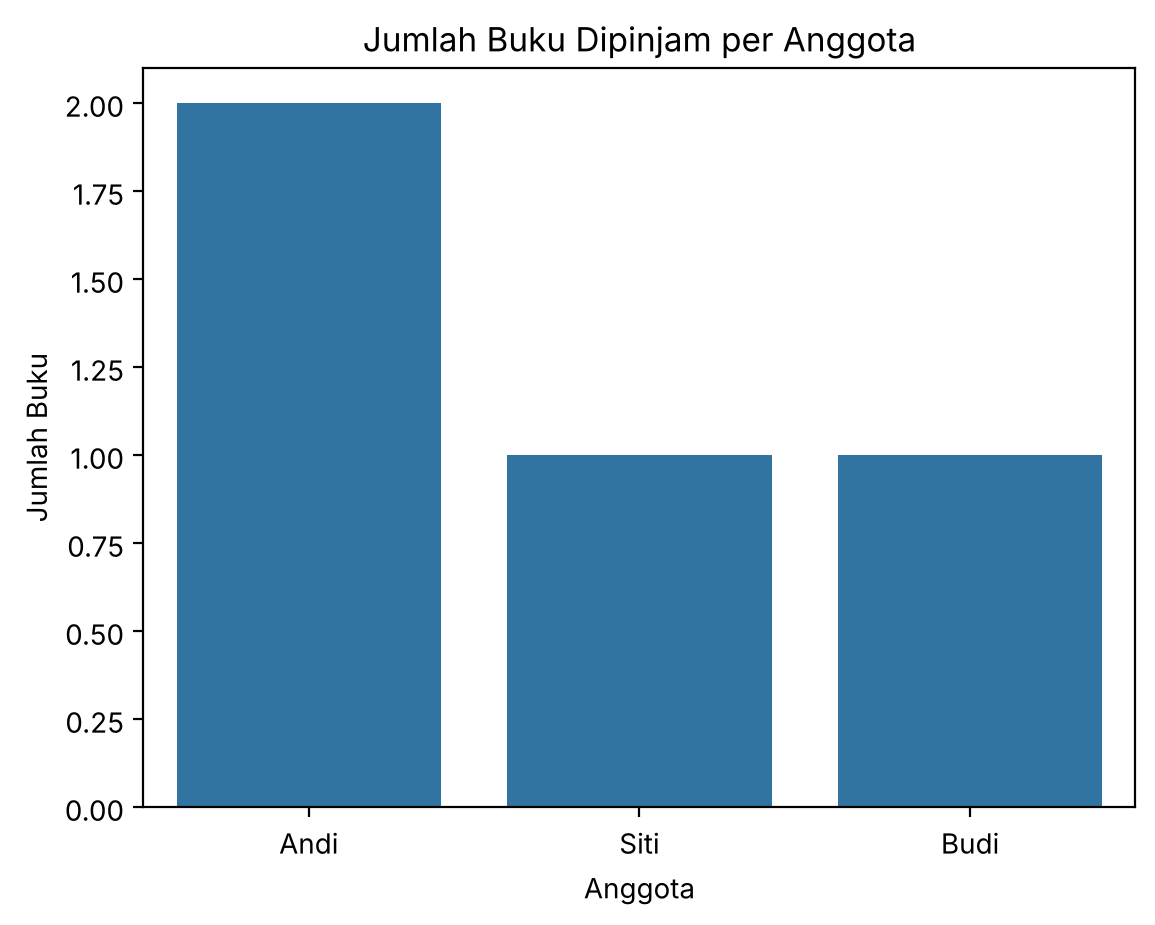

In [10]:
sns.barplot(data=df_jumlah, x='nama', y='jumlah_pinjam')
plt.title('Jumlah Buku Dipinjam per Anggota')
plt.xlabel('Anggota')
plt.ylabel('Jumlah Buku')
plt.show()

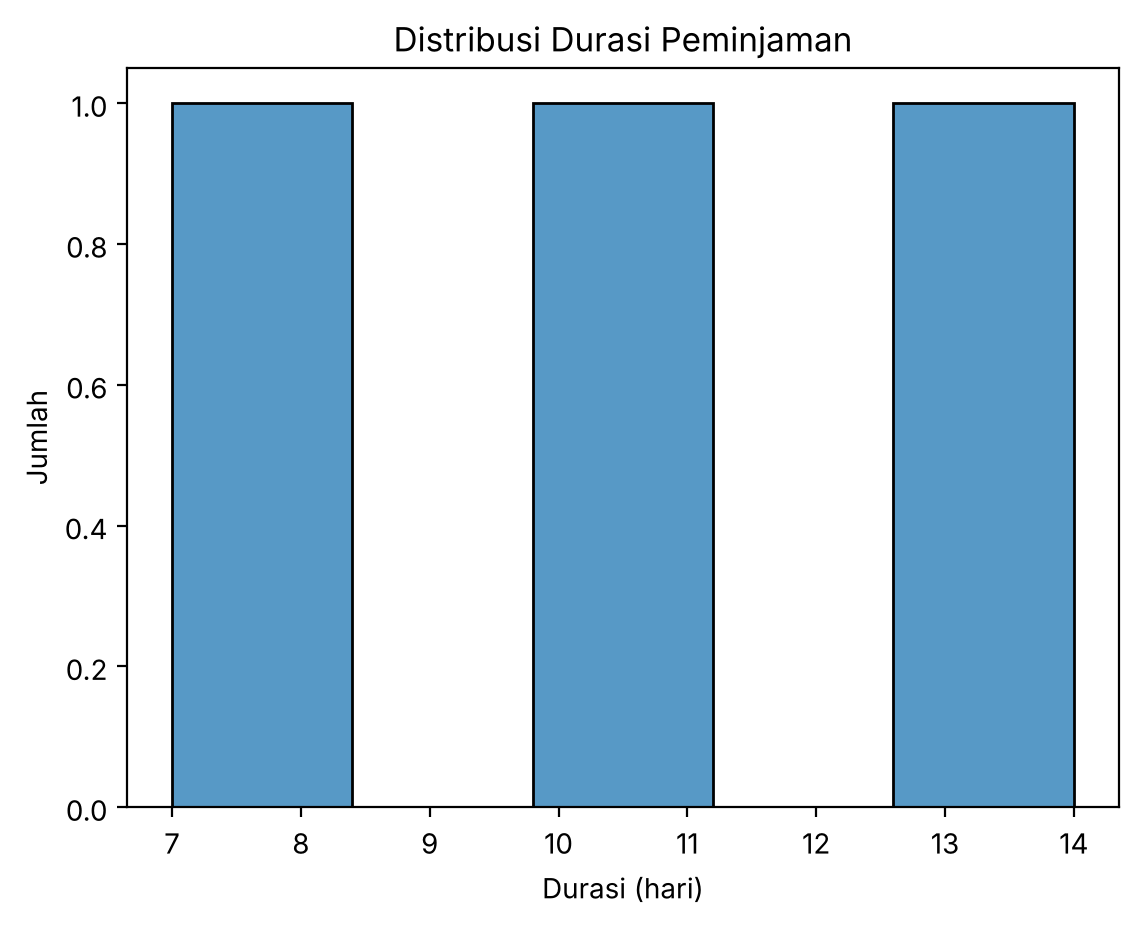

In [11]:
sns.histplot(df['durasi'].dropna(), bins=5)
plt.title('Distribusi Durasi Peminjaman')
plt.xlabel('Durasi (hari)')
plt.ylabel('Jumlah')
plt.show()

In [12]:
conn.close()